<a href="https://colab.research.google.com/github/CeliaCodes/CELIA-KAJIPOTEF/blob/main/02_gan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Waste Sorter · 02 Generative Adversarial Networks

**Week 2 milestone.** The trash class has the fewest images, and week 1 probably showed the weakest F1 there.
Can a GAN make extra trash images that help the classifier?

- **Part A:** a DCGAN trained on the trash class only, at 64 × 64
- **Part B:** retrain the week-1 ResNet-18 with 300 generated trash images added, and compare

Runtime → **T4 GPU**. Run `00_setup_and_data` first.

In [ ]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
ROOT = os.environ.get("WS_ROOT") or ("/content/drive/MyDrive/waste_sorter" if IN_COLAB else "./waste_sorter")
sys.path.insert(0, ROOT)
import ws_utils as ws
ws.setup(team="team_name_here")

import time, torch, torch.nn as nn
import matplotlib.pyplot as plt
from torchvision.utils import make_grid
dev = ws.device()

Mounted at /content/drive
Copying data from Drive to the local disk (once per session)...
Team: team_name_here | root: /content/drive/MyDrive/waste_sorter | device: cuda | smoke test: False


## Part A · DCGAN on the trash class
Pixels are scaled to [−1, 1] to match the generator's `tanh` output. Flips and small crops stretch the
roughly 100 training images a little further.

In [ ]:
from torch.utils.data import DataLoader
from torchvision import transforms as T
split = ws.load_split()
trash_paths = split[(split.split == "train") & (split.label == "trash")].path.tolist()
gan_tf = T.Compose([T.RandomResizedCrop(64, scale=(0.8, 1.0)), T.RandomHorizontalFlip(), T.ToTensor(),
                    T.Normalize((0.5,) * 3, (0.5,) * 3)])
trash_ds = ws.WasteDataset(trash_paths, [ws.CLASSES.index("trash")] * len(trash_paths), gan_tf)
trash_dl = DataLoader(trash_ds, batch_size=32, shuffle=True, drop_last=len(trash_ds) > 32)
print(len(trash_ds), "trash training images")

96 trash training images


**TODO 1 · Generator.** Map a noise vector `z` of shape (N, 100, 1, 1) to an image of shape (N, 3, 64, 64)
with `ConvTranspose2d` layers, following the DCGAN recipe from the lecture:

`100 → 512×4×4 → 256×8×8 → 128×16×16 → 64×32×32 → 3×64×64`

Use `ConvTranspose2d(c_in, c_out, 4, stride, padding, bias=False)` with stride 1 and padding 0 for the first
layer, stride 2 and padding 1 after that; `BatchNorm2d + ReLU` after every layer except the last, which
ends with `Tanh`.

In [ ]:
Z = 100

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # Input shape: (N, 100, 1, 1)
            nn.ConvTranspose2d(100, 512, kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
            # State: (N, 512, 4, 4)
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            # State: (N, 256, 8, 8)
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            # State: (N, 128, 16, 16)
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            # State: (N, 64, 32, 32)
            nn.ConvTranspose2d(64, 3, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
            # Output State: (N, 3, 64, 64)
        )

    def forward(self, z):
        return self.net(z)

**TODO 2 · Discriminator.** The mirror image: `3×64×64 → 64×32×32 → 128×16×16 → 256×8×8 → 512×4×4 → 1`.
Use `Conv2d(c_in, c_out, 4, 2, 1, bias=False)` and `LeakyReLU(0.2)`; `BatchNorm2d` on every layer except the
first. The last layer is `Conv2d(512, 1, 4, 1, 0)` followed by `Flatten`; output one **logit** per image
(no sigmoid: we use `BCEWithLogitsLoss`).

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # Input shape: (N, 3, 64, 64)
            nn.Conv2d(3, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # State: (N, 64, 32, 32)
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            # State: (N, 128, 16, 16)
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            # State: (N, 256, 8, 8)
            nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            # State: (N, 512, 4, 4)
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=0, bias=False),
            # Output State: (N, 1, 1, 1)
            nn.Flatten()
        )

    def forward(self, x):
        return self.net(x).view(-1)

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

ws.seed_everything()
G, D = Generator().to(dev), Discriminator().to(dev)
G.apply(init_weights); D.apply(init_weights)
z = torch.randn(4, Z, 1, 1, device=dev)
print("G(z):", tuple(G(z).shape), "| D(G(z)):", tuple(D(G(z)).shape))

G(z): (4, 3, 64, 64) | D(G(z)): (4,)


**TODO 3 · One training step.** Phase A updates D on a real batch (label 1) and a fake batch (label 0);
remember `.detach()`. Phase B updates G so that D labels new fakes as real. Use **label smoothing**: real
labels of 0.9 for D.

In [ ]:
bce = nn.BCEWithLogitsLoss()
optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))

def train_step(real):
    bs = real.size(0)
    z = torch.randn(bs, Z, 1, 1, device=dev)

    # Phase 1: Train Discriminator to maximize log(D(x)) + log(1 - D(G(z)))
    optD.zero_grad()

    # Real batch: apply 0.9 label smoothing to real targets
    label_real = torch.full((bs,), 0.9, device=dev)
    out_real = D(real)
    loss_real = bce(out_real, label_real)

    # Fake batch: label 0 (no label smoothing here)
    fake = G(z)
    label_fake = torch.zeros(bs, device=dev)
    out_fake = D(fake.detach())
    loss_fake = bce(out_fake, label_fake)

    d_loss = loss_real + loss_fake
    d_loss.backward()
    optD.step()

    # Phase 2: Train Generator to maximize log(D(G(z)))
    optG.zero_grad()
    label_g = torch.ones(bs, device=dev)
    out_g_fake = D(fake)
    g_loss = bce(out_g_fake, label_g)

    g_loss.backward()
    optG.step()

    return d_loss.item(), g_loss.item()

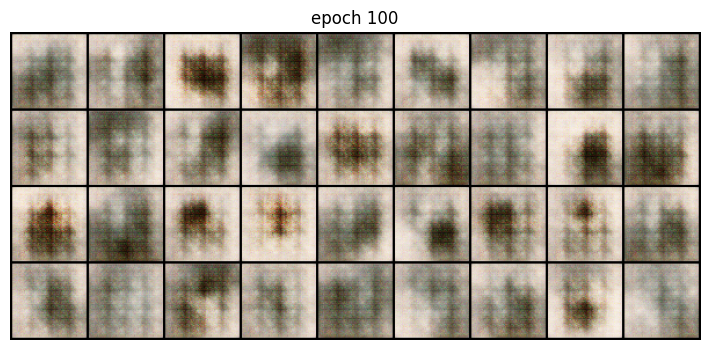

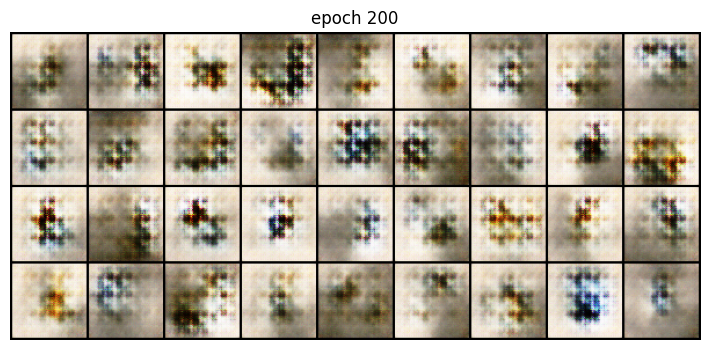

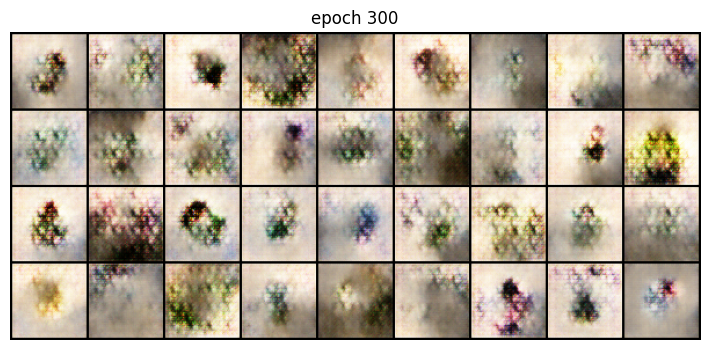

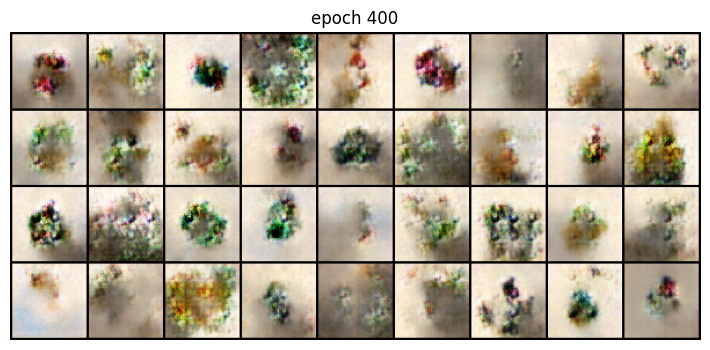

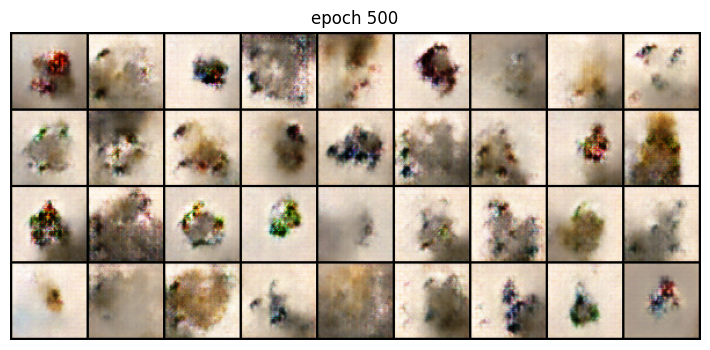

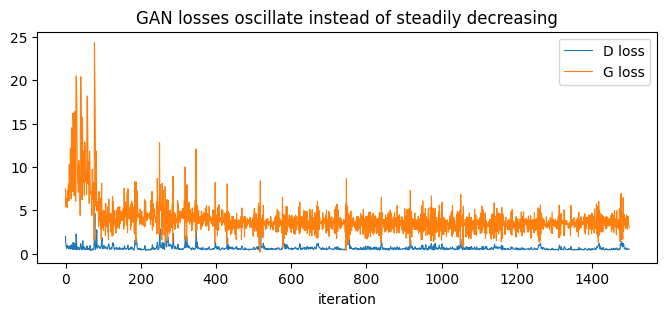

In [ ]:
EPOCHS = ws.epochs(500)
fixed_z = torch.randn(36, Z, 1, 1, device=dev)
d_hist, g_hist, t0 = [], [], time.time()
for ep in range(EPOCHS):
    for real, _ in trash_dl:
        d, g = train_step(real.to(dev))
        d_hist.append(d); g_hist.append(g)
    if (ep + 1) % 100 == 0 or ep + 1 == EPOCHS:
        G.eval()
        with torch.no_grad():
            grid = make_grid(G(fixed_z).cpu(), nrow=9, normalize=True, value_range=(-1, 1))
        G.train()
        plt.figure(figsize=(9, 4)); plt.imshow(grid.permute(1, 2, 0)); plt.axis("off")
        plt.title(f"epoch {ep + 1}"); plt.show()
gan_minutes = (time.time() - t0) / 60
torch.save(G.state_dict(), os.path.join(ws.ROOT, "checkpoints", "dcgan_trash_G.pt"))

plt.figure(figsize=(8, 3)); plt.plot(d_hist, label="D loss", lw=0.8); plt.plot(g_hist, label="G loss", lw=0.8)
plt.xlabel("iteration"); plt.legend(); plt.title("GAN losses oscillate instead of steadily decreasing"); plt.show()

Compare: real trash images (left) and generated ones (right). Look for **mode collapse**: many samples
that are nearly identical.

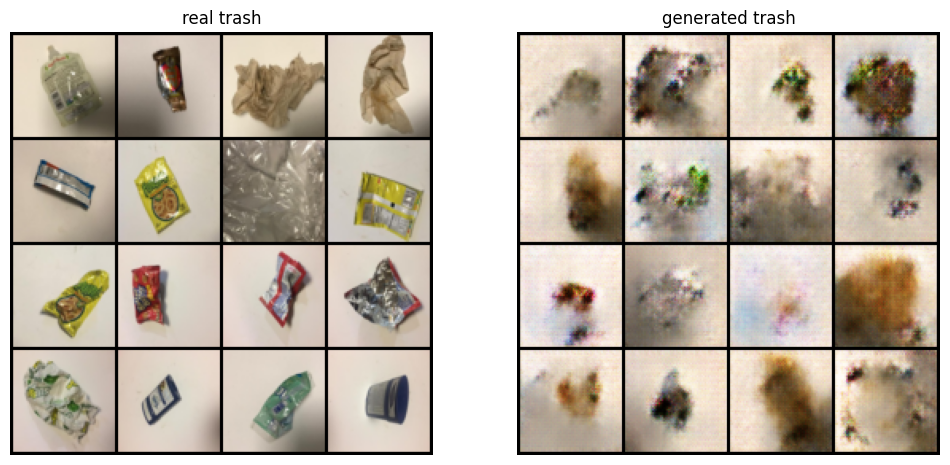

In [ ]:
real_batch = torch.stack([trash_ds[i][0] for i in range(min(16, len(trash_ds)))])
G.eval()
with torch.no_grad():
    fake_batch = G(torch.randn(16, Z, 1, 1, device=dev)).cpu()
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, b, t in [(ax[0], real_batch, "real trash"), (ax[1], fake_batch, "generated trash")]:
    a.imshow(make_grid(b, nrow=4, normalize=True, value_range=(-1, 1)).permute(1, 2, 0)); a.set_title(t); a.axis("off")
ws.save_figure(fig, "gan_real_vs_fake.png"); plt.show()

## Part B · Do generated images help the classifier?
We train the week-1 ResNet-18 twice with the **same seed and settings**: once on the normal training split,
once with 300 generated trash images added. Only the training data differs.

**TODO 4.** Generate 300 images with `G` (in eval mode, no gradients) and wrap them in
`ws.TensorImages(images, label_id, transform)` with the trash label and the evaluation transform at 224 px.

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights
from torchvision import transforms as T
weights = None if ws.SMOKE else ResNet18_Weights.DEFAULT
N_FAKE = 300

def make_resnet18():
    m = resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, len(ws.CLASSES))
    return m

# --- TODO 4: Generate 300 synthetic images ---
G.eval()
with torch.no_grad():
    z = torch.randn(N_FAKE, Z, 1, 1, device=dev)
    # G(z) produces tensor shaped (N_FAKE, 3, 64, 64) with range [-1, 1]
    fake_imgs = G(z).cpu()

# Construct standard validation/evaluation transform at 224px
# ws.TensorImages outputs PIL Images, so we must first convert to Tensor.
tf_eval = T.Compose([
    T.ToTensor(),
    T.Resize(224),
    T.CenterCrop(224),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

trash_idx = ws.CLASSES.index("trash")
synthetic = ws.TensorImages(fake_imgs, trash_idx, tf_eval)
# -----------------------------------------

print(len(synthetic), "synthetic trash images")

local_dl = ws.local_test_loader(224)
runs = {}
for name, extra in [("ResNet-18 baseline (week 2 rerun)", None), ("ResNet-18 + GAN images", synthetic)]:
    ws.seed_everything()
    model = make_resnet18()
    train_dl, val_dl, test_dl = ws.make_loaders(img_size=224, batch_size=32, extra_train=extra)
    minutes = ws.train_classifier(model, train_dl, val_dl, n_epochs=ws.epochs(5), lr=3e-4)
    test = ws.evaluate(model, test_dl)
    local = ws.evaluate(model, local_dl) if local_dl else None
    runs[name] = test
    ws.log_result(2, name, test, local, params_millions=ws.count_params(model), train_minutes=minutes,
                  notes=f"{N_FAKE if extra else 0} synthetic trash images; GAN trained {gan_minutes:.1f} min")

for name, m in runs.items():
    print(f"{name:35s} acc {m['accuracy']:.3f}  macro-F1 {m['macro_f1']:.3f}  trash F1 {m['trash_f1']:.3f}")

300 synthetic trash images
epoch 1/5  train loss 0.628  val acc 0.858  val macro-F1 0.844
epoch 2/5  train loss 0.160  val acc 0.865  val macro-F1 0.859
epoch 3/5  train loss 0.058  val acc 0.897  val macro-F1 0.886
epoch 4/5  train loss 0.020  val acc 0.913  val macro-F1 0.900
epoch 5/5  train loss 0.011  val acc 0.918  val macro-F1 0.905
Logged: {'method': 'ResNet-18 baseline (week 2 rerun)', 'test_accuracy': '0.9472', 'test_macro_f1': '0.9425', 'trash_f1': '0.9048', 'local_accuracy': '0.5345'}
epoch 1/5  train loss 0.540  val acc 0.792  val macro-F1 0.771
epoch 2/5  train loss 0.156  val acc 0.792  val macro-F1 0.777
epoch 3/5  train loss 0.067  val acc 0.892  val macro-F1 0.880
epoch 4/5  train loss 0.016  val acc 0.884  val macro-F1 0.867
epoch 5/5  train loss 0.009  val acc 0.894  val macro-F1 0.874
Logged: {'method': 'ResNet-18 + GAN images', 'test_accuracy': '0.9103', 'test_macro_f1': '0.8987', 'trash_f1': '0.8205', 'local_accuracy': '0.5000'}
ResNet-18 baseline (week 2 rerun) 

## Stretch ideas
- **Conditional GAN:** feed a class embedding into G and D and generate all six classes.
- **FID:** `torchmetrics.image.fid.FrechetInceptionDistance` compares real and generated feature statistics
  (lower is better). Compute it at epochs 100, 300 and 500.
- Try 100 and 1,000 synthetic images: is there a point where more hurts?

## Questions for your week-2 findings note
1. Did the synthetic images help, hurt or do nothing for trash F1 and macro-F1? Is the difference bigger than noise?
2. Describe the failure samples. Did you see mode collapse?
3. The GAN trained on about 100 images at 64 × 64, and its output is upscaled to 224 × 224. How might that limit it?
4. What did the loss curves tell you, and what did they not tell you?